In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import f_regression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import Lasso, Ridge, LassoCV, RidgeCV

In [2]:
df = pd.read_csv('ToyotaCorolla - MLR.csv')

In [3]:
df.shape

(1436, 11)

In [5]:
df.head()

,Price,Age_08_04,KM,Fuel_Type,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
0,13500,23,46986,Diesel,90,0,2000,3,4,5,1165
1,13750,23,72937,Diesel,90,0,2000,3,4,5,1165
2,13950,24,41711,Diesel,90,0,2000,3,4,5,1165
3,14950,26,48000,Diesel,90,0,2000,3,4,5,1165
4,13750,30,38500,Diesel,90,0,2000,3,4,5,1170


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Price      1436 non-null   int64 
 1   Age_08_04  1436 non-null   int64 
 2   KM         1436 non-null   int64 
 3   Fuel_Type  1436 non-null   object
 4   HP         1436 non-null   int64 
 5   Automatic  1436 non-null   int64 
 6   cc         1436 non-null   int64 
 7   Doors      1436 non-null   int64 
 8   Cylinders  1436 non-null   int64 
 9   Gears      1436 non-null   int64 
 10  Weight     1436 non-null   int64 
dtypes: int64(10), object(1)
memory usage: 123.5+ KB


**1.Perform exploratory data analysis (EDA) to gain insights into the dataset. Provide visualizations and summary statistics of the variables. Pre-process the data to apply the MLR.**

**EDA**

In [6]:
#Handling missing values
df.isnull().sum()

,0
Price,0
Age_08_04,0
KM,0
Fuel_Type,0
HP,0
Automatic,0
cc,0
Doors,0
Cylinders,0
Gears,0


In [7]:
#checking duplicates
df.duplicated().sum()

np.int64(1)

In [8]:
#dropping duplicates
df.drop_duplicates(inplace = True)

In [9]:
df.duplicated().sum()

np.int64(0)

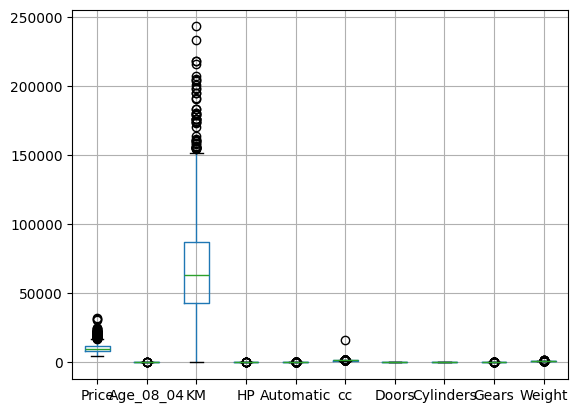

In [10]:
#checking outliers
df.boxplot()
plt.show()

In [11]:
#outlier capping for removing outliers
def outlier_capping(df, column):
  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)
  IQR = Q3 - Q1
  lower_extreme = Q1 - 1.5*IQR
  upper_extreme = Q3 + 1.5*IQR
  df[column] = df[column].apply(lambda x: lower_extreme if x<lower_extreme else upper_extreme if x>upper_extreme else x)
for col in df.select_dtypes(['int']).columns:
  outlier_capping(df, col)

**visualizations and summary statistics**

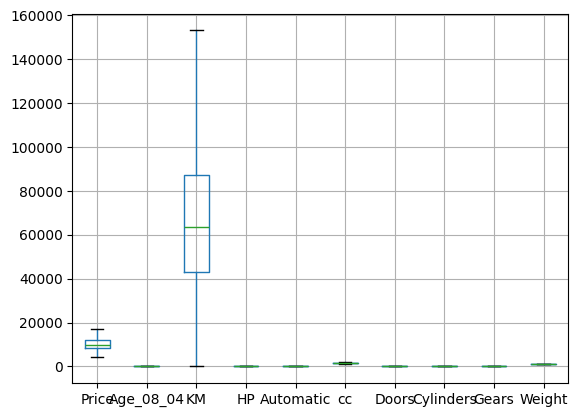

In [12]:
##visualisation
df.boxplot()
plt.show()

In [13]:
##statistics summary
df.describe()

,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
count,1435.000000,1435.000000,1435.000000,1435.000000,1435.0,1435.000000,1435.000000,1435.0,1435.0,1435.000000
mean,10495.964460,55.992334,67644.520383,101.093380,0.0,1558.327526,4.032753,4.0,5.0,1068.520906
std,2977.598549,18.529725,34725.393258,13.146145,0.0,168.788311,0.952667,0.0,0.0,37.722708
min,4350.000000,5.000000,1.000000,69.000000,0.0,1300.000000,2.000000,4.0,5.0,1000.000000
25%,8450.000000,44.000000,43000.000000,90.000000,0.0,1400.000000,3.000000,4.0,5.0,1040.000000
50%,9900.000000,61.000000,63451.000000,110.000000,0.0,1600.000000,4.000000,4.0,5.0,1070.000000
75%,11950.000000,70.000000,87041.500000,110.000000,0.0,1600.000000,5.000000,4.0,5.0,1085.000000
max,17200.000000,80.000000,153103.750000,140.000000,0.0,1900.000000,5.000000,4.0,5.0,1152.500000


**Pre-processing the data**

In [14]:
#set dummies for labeling
df = pd.get_dummies(df, dtype='int')
df

,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight,Fuel_Type_CNG,Fuel_Type_Diesel,Fuel_Type_Petrol
0,13500.0,23.0,46986.0,90.0,0.0,1900.0,3,4,5.0,1152.5,0,1,0
1,13750.0,23.0,72937.0,90.0,0.0,1900.0,3,4,5.0,1152.5,0,1,0
2,13950.0,24.0,41711.0,90.0,0.0,1900.0,3,4,5.0,1152.5,0,1,0
3,14950.0,26.0,48000.0,90.0,0.0,1900.0,3,4,5.0,1152.5,0,1,0
4,13750.0,30.0,38500.0,90.0,0.0,1900.0,3,4,5.0,1152.5,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1431,7500.0,69.0,20544.0,86.0,0.0,1300.0,3,4,5.0,1025.0,0,0,1
1432,10845.0,72.0,19000.0,86.0,0.0,1300.0,3,4,5.0,1015.0,0,0,1
1433,8500.0,71.0,17016.0,86.0,0.0,1300.0,3,4,5.0,1015.0,0,0,1
1434,7250.0,70.0,16916.0,86.0,0.0,1300.0,3,4,5.0,1015.0,0,0,1


**Explanation:**
---

First, I performed exploratory data analysis by checking for missing values and duplicate records. One duplicate row was found and dropped. Outliers were identified using boxplots and handled using outlier capping. Boxplot were also used for visualization, and statistical summary was obtained using the describe.

For preprocessing, the categorical column Fuel_Type, which is a nominal column, was converted into numerical form using set dummies. This step was required to make the data suitable for multiple linear regression. Other preprocessing steps will be performed in the next tasks before building the regression models.

**2.Split the dataset into training and testing sets (e.g., 80% training, 20% testing).**








In [15]:
target = df[['Price']]
features = df.drop(columns = ['Price'])

In [16]:
x_train, x_test, y_train, y_test = train_test_split(features, target, train_size = 0.8, random_state = 100)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(1148, 12)
(287, 12)
(1148, 1)
(287, 1)


**Explanation:**
---

First, I selected Price column as the target and all other columns as features. Then, the dataset was split into 80% training data and 20% testing data. The training set is used to build the model, and the testing set is used to evaluate its performance.

**3.Build a multiple linear regression model using the training dataset. Interpret the coefficients of the model. Build a minimum of 3 different models.**

#MODEL-1:
Multiple Linear Regression(All features)

In [17]:
#features for model-1
target = df[['Price']]
features_m1 = df.drop(columns = ['Price'])

In [18]:
x_train1, x_test1, y_train1, y_test1 = train_test_split(features_m1, target, train_size = 0.8, random_state = 100)
print(x_train1.shape)
print(x_test1.shape)
print(y_train1.shape)
print(y_test1.shape)


(1148, 12)
(287, 12)
(1148, 1)
(287, 1)


In [19]:
model_1 = LinearRegression()
model_1.fit(x_train1, y_train1)

LinearRegression()

In [20]:
model_1.coef_

array([[-1.05415897e+02, -1.49023022e-02,  2.69057488e+01,
        -2.91322522e-13, -2.53755357e+00, -9.09815382e+01,
         4.26325641e-14, -1.13686838e-13,  2.55822335e+01,
        -7.05325746e+02,  3.12879977e+02,  3.92445770e+02]])

In [21]:
#converting array to dataframe
coef_df = pd.DataFrame({
    'Features': x_train1.columns,
    'Coefficients': model_1.coef_[0]
})
coef_df

,Features,Coefficients
0,Age_08_04,-1.054159e+02
1,KM,-1.490230e-02
2,HP,2.690575e+01
3,Automatic,-2.913225e-13
4,cc,-2.537554e+00
5,Doors,-9.098154e+01
6,Cylinders,4.263256e-14
7,Gears,-1.136868e-13
8,Weight,2.558223e+01
9,Fuel_Type_CNG,-7.053257e+02


In [22]:
model_1.intercept_

array([-8696.48638816])

#MODEL-2:

Feature Selection model

In [23]:
#as target is numerical, i choose f-reg for feature selection
f_reg = f_regression(features, target)
f_reg

(array([5.79099779e+03, 8.40165852e+02, 9.91828244e+01, 0.00000000e+00,
        2.43847136e+01, 4.96579374e+01, 0.00000000e+00, 0.00000000e+00,
        4.97966391e+02, 2.24343934e+00, 3.57282723e-03, 3.10225191e-01]),
 array([0.00000000e+000, 9.19507250e-146, 1.22819794e-022, 1.00000000e+000,
        8.81431719e-007, 2.83450155e-012, 1.00000000e+000, 1.00000000e+000,
        6.45615931e-095, 1.34402459e-001, 9.52344660e-001, 5.77629009e-001]))

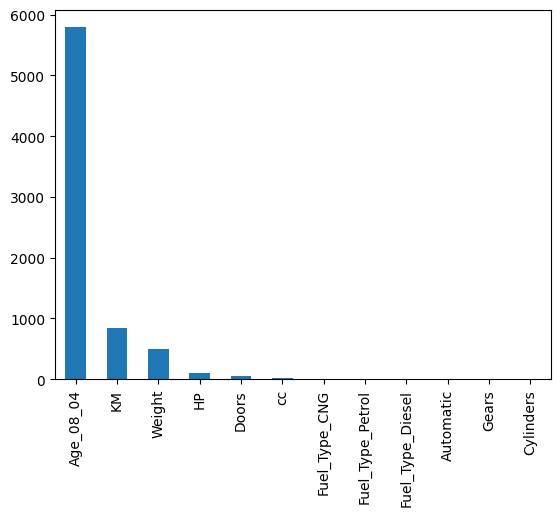

In [24]:
pd.Series(f_reg[0], index = features.columns).sort_values(ascending = False).plot(kind='bar')
plt.show()

In [25]:
#dropping the least important features(last 6) based on above visualisation
df.drop(columns = ['Cylinders', 'Gears', 'Automatic', 'Fuel_Type_Diesel', 'Fuel_Type_CNG', 'Fuel_Type_Petrol'], inplace = True)


In [26]:
df.head()

,Price,Age_08_04,KM,HP,cc,Doors,Weight
0,13500.0,23.0,46986.0,90.0,1900.0,3,1152.5
1,13750.0,23.0,72937.0,90.0,1900.0,3,1152.5
2,13950.0,24.0,41711.0,90.0,1900.0,3,1152.5
3,14950.0,26.0,48000.0,90.0,1900.0,3,1152.5
4,13750.0,30.0,38500.0,90.0,1900.0,3,1152.5


In [27]:
target = df[['Price']]
features_m2 = df.drop(columns = ['Price'])

In [28]:
x_train2, x_test2, y_train2, y_test2 = train_test_split(features_m2, target, train_size = 0.8, random_state = 100)
print(x_train2.shape)
print(x_test2.shape)
print(y_train2.shape)
print(y_test2.shape)

(1148, 6)
(287, 6)
(1148, 1)
(287, 1)


In [29]:
model_2 = LinearRegression()
model_2.fit(x_train2, y_train2)

LinearRegression()

In [30]:
model_2.coef_

array([[-1.05292763e+02, -1.58095486e-02,  2.64810353e+01,
        -2.45717156e+00, -8.16564146e+01,  2.46270159e+01]])

In [31]:
#converting array to dataframe
coef_df = pd.DataFrame({
    'Features': x_train2.columns,
    'Coefficients': model_2.coef_[0]
})
coef_df

,Features,Coefficients
0,Age_08_04,-105.292763
1,KM,-0.015810
2,HP,26.481035
3,cc,-2.457172
4,Doors,-81.656415
5,Weight,24.627016


In [32]:
model_2.intercept_

array([-7371.00404515])

#MODEL-3

Scaled Model

In [33]:
target = df[['Price']]
features_m3 = df.drop(columns = ['Price'])

In [34]:
x_train3, x_test3, y_train3, y_test3 = train_test_split(features_m3, target, train_size = 0.8, random_state = 100)
print(x_train3.shape)
print(x_test3.shape)
print(y_train3.shape)
print(y_test3.shape)

(1148, 6)
(287, 6)
(1148, 1)
(287, 1)


In [35]:
#scaling the required numerical columns
scaled_cols = ['KM', 'cc', 'Weight']

In [36]:
std_sca = StandardScaler()
x_train3[scaled_cols] = std_sca.fit_transform(x_train3[scaled_cols])
x_test3[scaled_cols] = std_sca.transform(x_test3[scaled_cols])

In [37]:
model_3 = LinearRegression()
model_3.fit(x_train3, y_train3)

LinearRegression()

In [38]:
model_3.coef_

array([[-105.29276276, -545.84661718,   26.48103525, -421.70274935,
         -81.65641464,  946.39289947]])

In [39]:
#converting array to dataframe
coef_df = pd.DataFrame({
    'Features': x_train3.columns,
    'Coefficients': model_3.coef_[0]
})
coef_df

,Features,Coefficients
0,Age_08_04,-105.292763
1,KM,-545.846617
2,HP,26.481035
3,cc,-421.702749
4,Doors,-81.656415
5,Weight,946.392899


In [40]:
model_3.intercept_

array([14046.7084748])

**Explanation:**
---

In this step, three multiple linear regression models were built.

**Model-1** was trained using all available features.

**Model-2** was built after performing feature selection to remove less important variables.

**Model-3** was built using standardized features to check the impact of scaling.

⸻

Separate feature sets were created for each model to ensure consistency between training and testing data during evaluation.


⸻

**Interpretation of Coefficients**

The coefficients indicate the direction and strength of the relationship between each feature and the target (Price). The sign of the coefficients shows the direction of the relationship with price.
A positive coefficient means the feature increases the car price, while a negative coefficient means the price decreases as the feature increases.
Features with larger absolute coefficient values have a stronger impact on the price compared to others.

**4.Evaluate the performance of the model using appropriate evaluation metrics on the testing dataset.**

In [41]:
def evaluate_model(model, x_test, y_test):
  y_pred = model.predict(x_test)

  r_square = r2_score(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)
  mae = mean_absolute_error(y_test, y_pred)
  rmse = np.sqrt(mse)

  print("R-squared:", r_square)
  print("Mean Squared Error:", mse)
  print("Mean Absolute Error:", mae)
  print("Root Mean Squared Error:", rmse)

In [42]:
#evaluating model-1
print("Model 1 Evaluation:")
print("------------------")
evaluate_model(model_1, x_test1, y_test1)

Model 1 Evaluation:
------------------
R-squared: 0.8505975113400095
Mean Squared Error: 1265987.7870391596
Mean Absolute Error: 827.6257664686774
Root Mean Squared Error: 1125.1612271310985


In [43]:
#evaluating model-2
print("Model 2 Evaluation:")
print("------------------")
evaluate_model(model_2, x_test2, y_test2)

Model 2 Evaluation:
------------------
R-squared: 0.8473627877706413
Mean Squared Error: 1293397.7757883256
Mean Absolute Error: 837.5200864916536
Root Mean Squared Error: 1137.2764728896511


In [44]:
#evaluating model-3
print("Model 3 Evaluation:")
print("------------------")
evaluate_model(model_3, x_test3, y_test3)

Model 3 Evaluation:
------------------
R-squared: 0.8473627877706413
Mean Squared Error: 1293397.7757883251
Mean Absolute Error: 837.5200864916535
Root Mean Squared Error: 1137.276472889651


**Explanation:**
---

The performance of all three models was evaluated using R-squared(r2), Mean Squared Error (MSE), Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).
All three models produced similar results, indicating consistent performance.
Model-1 achieved the best R-squared value, while Model-2 and Model-3 give similar values because scaling does not affect linear regression models.

**5.Apply Lasso and Ridge methods on the model.**

#Lasso Method

In [45]:
lasso =Lasso(alpha = 0.01)
lasso.fit(x_train3, y_train3)

Lasso(alpha=0.01)

In [46]:
lasso_pred = Lasso.predict(lasso, x_test3)
r2_score(y_test3, lasso_pred)

0.8473634462465778

#Ridge Method

In [47]:
#instead of ridge i used ridge_cv
ridge_cv = RidgeCV(alphas = [0.01, 0.1, 1, 7, 10, 100], cv=5)
ridge_cv.fit(x_train3, y_train3)

RidgeCV(alphas=[0.01, 0.1, 1, 7, 10, 100], cv=5)

In [48]:
ridge_cv_pred = ridge_cv.predict(x_test3)
r2_score( y_test3, ridge_cv_pred)

0.8474176057474303

**Explanation:**
---

First, Lasso regression was applied on the scaled data and the R² score was calculated. Lasso helps in feature selection by reducing some coefficients to zero. Next, Ridge regression was applied using RidgeCV, which automatically selects the best alpha value using cross-validation. Ridge helps in reducing multicollinearity and improving model stability.